# Calculus

In [1]:
# Import NumPy and Matplotlib for this notebook.

import numpy as np
import matplotlib.pyplot as plt

## 중심차분법을 이용한 수치 미분

$f(x) = x^2$의 $x = 3$에서의 미분값을 중심차분법으로 근사한다.

$$f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}$$

$h = 10^{-5}$로 계산하고, 해석적 미분값 $f'(3) = 2 \times 3 = 6$과의 절대 오차가 $10^{-4}$ 이하인지 확인한다.

In [2]:
# Define the quadratic function and numerical differentiation parameters.

# Evaluate f(x) = x^2.
def f(x):
    return x ** 2


x = 3.0
h = 1e-5

In [3]:
# Approximate the derivative using function values on both sides of x.

# The two evaluation points are 2h apart, so divide by 2h.
numerical_derivative = (f(x + h) - f(x - h)) / (2 * h)

In [4]:
# Compare with the analytical derivative and verify the absolute error.

analytical_derivative = 2 * x
absolute_error = abs(numerical_derivative - analytical_derivative)
tolerance = 1e-4

print(f"Central difference: {numerical_derivative:.12f}")
print(f"Analytical derivative: {analytical_derivative:.12f}")
print(f"Absolute error: {absolute_error:.3e}")
assert absolute_error <= tolerance, f"Absolute error exceeds {tolerance:.0e}."
print(f"Verified: absolute error <= {tolerance:.0e}")

Central difference: 6.000000000039
Analytical derivative: 6.000000000000
Absolute error: 3.931e-11
Verified: absolute error <= 1e-04


## 2변수 함수의 등고선

$f(x, y) = x^2 + y^2$를 $-3 \le x, y \le 3$ 범위에서 계산하고 등고선을 그린다.

함숫값이 양수 $c$인 등고선은 $x^2 + y^2 = c$이므로, 원점을 중심으로 반지름이 $\sqrt{c}$인 원이다. 각 등고선의 숫자와 색상 막대는 함숫값을 나타낸다.

In [5]:
# Create a two-dimensional grid of x and y coordinates.

x_values = np.linspace(-3, 3, 301)
y_values = np.linspace(-3, 3, 301)
# X and Y both have shape (301, 301), with one (x, y) pair per grid point.
X, Y = np.meshgrid(x_values, y_values)

In [6]:
# Evaluate f(x, y) = x^2 + y^2 at every grid point.

Z = X ** 2 + Y ** 2

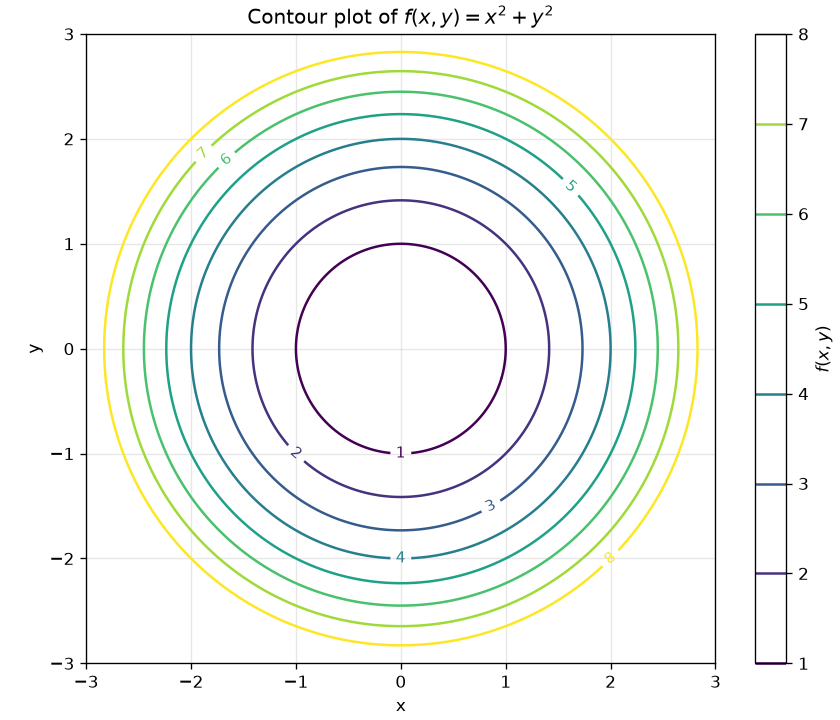

In [7]:
# Plot labeled contours and a color bar for the function values.

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
contours = ax.contour(X, Y, Z, levels=np.arange(1, 9), cmap="viridis")
ax.clabel(contours, inline=True, fontsize=9, fmt="%g")
fig.colorbar(contours, ax=ax, label=r"$f(x, y)$")
# Equal axis scales preserve the circular shape of the level sets.
ax.set_aspect("equal")
ax.set(xlabel="x", ylabel="y", title=r"Contour plot of $f(x, y) = x^2 + y^2$")
ax.grid(True, alpha=0.3)
plt.show()